# 25. Molecular Featurization II: Fingerprints
@Shengli (Bruce) Jiang, University of South Carolina

## What We Covered in the Last Lecture

- Read SMILES strings and inspect molecular graphs with RDKit.
- Construct one-hot encodings and atom-count and bond-count vectors.
- Identify structures that share the same count vector.

## Today's Learning Objectives

- Explain how Morgan fingerprints encode local atomic environments.
- Generate binary and count fingerprints with RDKit.
- Calculate Tanimoto similarity and rank molecules against a reference.

## Setup

If needed, run `%pip install rdkit numpy pandas pillow` once, then restart the kernel.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import Draw, rdFingerprintGenerator

draw_options = Draw.MolDrawOptions()
draw_options.useBWAtomPalette()
draw_options.legendFontSize = 18
draw_options.legendFraction = 0.20

print('RDKit version:', rdBase.rdkitVersion)

RDKit version: 2026.03.5


## RDKit Refresher

`MolFromSmiles()` reads a SMILES string and returns a molecular graph.

In [2]:
mol = Chem.MolFromSmiles('CCCO')

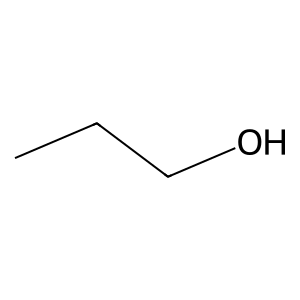

In [3]:
Draw.MolToImage(mol, options=draw_options)

In [4]:
Chem.MolToSmiles(mol)

'CCCO'

### Atoms and Bonds

Atom and bond indices start at zero. These molecules use implicit hydrogens, so graph counts include only heavy atoms and their bonds.

In [5]:
print('Atoms:', mol.GetNumAtoms())
print('Bonds:', mol.GetNumBonds())

Atoms: 4
Bonds: 3


In [6]:
atom = mol.GetAtomWithIdx(0)
print('Element:', atom.GetSymbol())
print('Heavy-atom neighbors:', atom.GetDegree())
print('Attached H:', atom.GetTotalNumHs())

Element: C
Heavy-atom neighbors: 1
Attached H: 3


In [7]:
for atom in mol.GetAtoms():
    print(atom.GetIdx(), atom.GetSymbol(), atom.GetTotalNumHs())

0 C 3
1 C 2
2 C 2
3 O 1


In [8]:
bond = mol.GetBondWithIdx(0)
print('Bond type:', bond.GetBondType())
print('Connected atom indices:', bond.GetBeginAtomIdx(), bond.GetEndAtomIdx())

Bond type: SINGLE
Connected atom indices: 0 1


### Showing Two Molecules

In [9]:
propanol_1 = mol
propanol_2 = Chem.MolFromSmiles('CC(O)C')

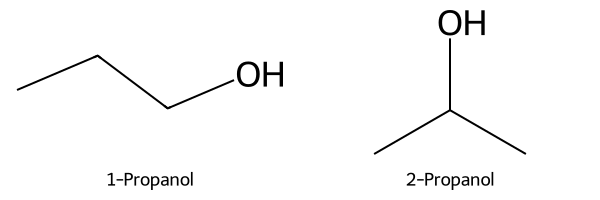

In [10]:
Draw.MolsToGridImage(
    [propanol_1, propanol_2], legends=['1-Propanol', '2-Propanol'],
    molsPerRow=2, subImgSize=(300, 200), drawOptions=draw_options,
)

## Limits of Atom and Bond Counts

Count heavy atoms and single bonds in 1-propanol and 2-propanol.

In [11]:
propanols = {'1-Propanol': propanol_1, '2-Propanol': propanol_2}
rows = []
for name, mol in propanols.items():
    elements = [atom.GetSymbol() for atom in mol.GetAtoms()]
    bonds = [tuple(sorted([bond.GetBeginAtom().GetSymbol(),
                           bond.GetEndAtom().GetSymbol()]))
             for bond in mol.GetBonds()]
    rows.append([elements.count('C'), elements.count('O'),
                 bonds.count(('C', 'C')), bonds.count(('C', 'O'))])

display(pd.DataFrame(rows, index=list(propanols),
                     columns=['C atoms', 'O atoms', 'C-C single', 'C-O single']))

,C atoms,O atoms,C-C single,C-O single
1-Propanol,3,1,2,1
2-Propanol,3,1,2,1


Both molecules give `[3, 1, 2, 1]`. Local environments can distinguish them.

## Morgan Fingerprints

An initial label describes each atom. Each update combines the center's label with its neighbors' labels and bond types. The fingerprint collects features from radius 0 through the chosen radius.

Use radius 2, 2048 positions, and chirality enabled throughout.

In [12]:
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048, includeChirality=True,
)

In [13]:
fp_1 = generator.GetFingerprint(propanol_1)
len(fp_1)

2048

In [14]:
fp_1.GetNumOnBits()

8

In [15]:
fp_2 = generator.GetFingerprint(propanol_2)
fp_1 == fp_2

False

### Growing a Local Environment

For `CCCCO` and `CCCCN`, select atom 2, a CH₂ center two bonds from O or N. The center's feature identifiers match at radii 0 and 1, then differ at radius 2.

In [16]:
butanol = Chem.MolFromSmiles('CCCCO')
butylamine = Chem.MolFromSmiles('CCCCN')

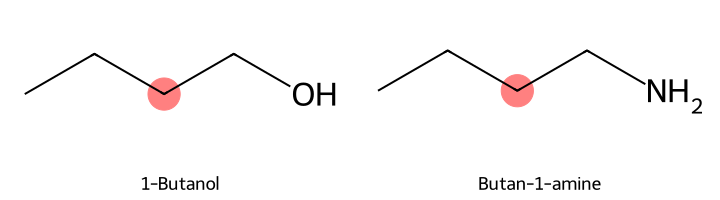

In [17]:
Draw.MolsToGridImage(
    [butanol, butylamine], legends=['1-Butanol', 'Butan-1-amine'],
    molsPerRow=2, subImgSize=(360, 200),
    highlightAtomLists=[[2], [2]], drawOptions=draw_options,
)

In [18]:
center = butanol.GetAtomWithIdx(2)
print('Attached H:', center.GetTotalNumHs())
print('Neighbor elements:', [atom.GetSymbol() for atom in center.GetNeighbors()])

Attached H: 2
Neighbor elements: ['C', 'C']


`AdditionalOutput` records which atom and radius generated each feature. Each entry maps a feature identifier to `(atom index, radius)` pairs.

In [19]:
info = rdFingerprintGenerator.AdditionalOutput()
info.AllocateBitInfoMap()
butanol_features = generator.GetSparseCountFingerprint(butanol, additionalOutput=info)
info.GetBitInfoMap()

{864662311: ((4, 0),),
 1173125914: ((1, 1),),
 1510461303: ((2, 1),),
 1535166686: ((4, 1),),
 1685248591: ((1, 2),),
 1828340842: ((3, 2),),
 1973275706: ((2, 2),),
 2245384272: ((1, 0), (2, 0), (3, 0)),
 2246728737: ((0, 0),),
 3542456614: ((0, 1),),
 4023654873: ((3, 1),)}

In [20]:
chains = {'1-Butanol': butanol, 'Butan-1-amine': butylamine}
rows = []
for name, mol in chains.items():
    info = rdFingerprintGenerator.AdditionalOutput()
    info.AllocateBitInfoMap()
    generator.GetSparseCountFingerprint(mol, additionalOutput=info)
    row = {'Molecule': name}
    for identifier, occurrences in info.GetBitInfoMap().items():
        for atom_index, radius in occurrences:
            if atom_index == 2:
                row[f'Radius {radius}'] = identifier
    rows.append(row)

display(pd.DataFrame(rows).set_index('Molecule')
        [['Radius 0', 'Radius 1', 'Radius 2']])

,Radius 0,Radius 1,Radius 2
Molecule,,,
1-Butanol,2245384272,1510461303,1973275706
Butan-1-amine,2245384272,1510461303,3538804691


In [21]:
smiles = {
    'Phenol': 'Oc1ccccc1',
    'Cyclohexanol': 'OC1CCCCC1',
    'Anisole': 'COc1ccccc1',
    'Catechol': 'Oc1ccccc1O',
    'Benzene': 'c1ccccc1',
    'p-Cresol': 'Cc1ccc(O)cc1',
}
molecules = {name: Chem.MolFromSmiles(s) for name, s in smiles.items()}

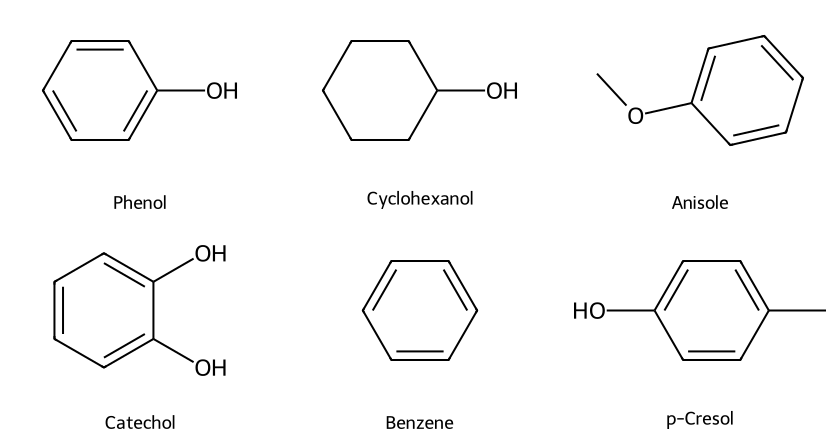

In [22]:
Draw.MolsToGridImage(
    list(molecules.values()), legends=list(molecules),
    molsPerRow=3, subImgSize=(280, 220), drawOptions=draw_options,
)

### Binary Fingerprints

`GetFingerprint()` returns a bit vector. `GetFingerprintAsNumPy()` returns an array. Each molecule becomes one row of the feature matrix.

In [23]:
phenol = molecules['Phenol']
phenol_fp = generator.GetFingerprint(phenol)
list(phenol_fp.GetOnBits())

[65, 389, 745, 807, 1088, 1199, 1380, 1602, 1750, 1778, 1873]

In [24]:
phenol_array = generator.GetFingerprintAsNumPy(phenol)
phenol_array

array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8)

In [25]:
fingerprints = {name: generator.GetFingerprint(mol)
                for name, mol in molecules.items()}
X = np.vstack([generator.GetFingerprintAsNumPy(mol)
               for mol in molecules.values()])

print('Feature-matrix shape:', X.shape)
display(pd.DataFrame({'SMILES': smiles,
                      'Active bits': {name: fp.GetNumOnBits()
                                      for name, fp in fingerprints.items()}}))

Feature-matrix shape: (6, 2048)


,SMILES,Active bits
Phenol,Oc1ccccc1,11
Cyclohexanol,OC1CCCCC1,11
Anisole,COc1ccccc1,14
Catechol,Oc1ccccc1O,10
Benzene,c1ccccc1,3
p-Cresol,Cc1ccc(O)cc1,13


### Feature Identifiers and Bit Positions

For these Morgan fingerprints, a feature identifier maps to `identifier % 2048`. Different identifiers can map to the same position, causing a hash collision.

Find phenol's O–H atom feature at radius 0.

In [26]:
oxygen_index = next(atom.GetIdx() for atom in phenol.GetAtoms()
                    if atom.GetSymbol() == 'O')
info = rdFingerprintGenerator.AdditionalOutput()
info.AllocateBitInfoMap()
generator.GetSparseCountFingerprint(phenol, additionalOutput=info)
feature_id = next(identifier for identifier, occurrences in info.GetBitInfoMap().items()
                  if (oxygen_index, 0) in occurrences)
feature_id

864662311

In [27]:
bit = feature_id % 2048
print('Bit position:', bit)
print('Bit value:', phenol_fp[bit])

Bit position: 807
Bit value: 1


### Binary and Count Fingerprints

Binary fingerprints record presence. Count fingerprints retain occurrences. Compare the O–H atom feature in phenol and catechol.

In [28]:
phenol_counts = generator.GetCountFingerprint(phenol)
phenol_counts[bit]

1

In [29]:
rows = []
for name in ['Phenol', 'Catechol']:
    counts = generator.GetCountFingerprint(molecules[name])
    rows.append([fingerprints[name][bit], counts[bit]])

display(pd.DataFrame(rows, index=['Phenol', 'Catechol'],
                     columns=[f'Bit {bit}', f'Count at {bit}']))

,Bit 807,Count at 807
Phenol,1,1
Catechol,1,2


## Tanimoto Similarity

For binary fingerprints, let $a$ and $b$ be the numbers of active bits and $c$ the number shared:

$$T(A,B)=\frac{c}{a+b-c}=\frac{|A\cap B|}{|A\cup B|}.$$

Shared zeros do not contribute. Compare phenol and cyclohexanol.

In [30]:
cyclohexanol_fp = fingerprints['Cyclohexanol']
similarity = DataStructs.TanimotoSimilarity(phenol_fp, cyclohexanol_fp)
similarity

0.047619047619047616

In [31]:
A = set(fingerprints['Phenol'].GetOnBits())
B = set(fingerprints['Cyclohexanol'].GetOnBits())
shared_ones = len(A & B)
shared_zeros = 2048 - len(A | B)
different = len(A ^ B)

display(pd.DataFrame({'Bit positions': [shared_zeros, shared_ones, different]},
                     index=['Both 0', 'Both 1', 'Different values']))
agreement = (shared_zeros + shared_ones) / 2048
manual = shared_ones / len(A | B)
print(f'Bit-value agreement: {agreement:.3%}')
print(f'Tanimoto by counting: {manual:.6f}')
print(f'Tanimoto from RDKit: {similarity:.6f}')

,Bit positions
Both 0,2027
Both 1,1
Different values,20


Bit-value agreement: 99.023%
Tanimoto by counting: 0.047619
Tanimoto from RDKit: 0.047619


## Ranking Candidates

Compare each candidate with phenol using the same fingerprint settings.

In [32]:
scores = {
    name: DataStructs.TanimotoSimilarity(fingerprints['Phenol'], fp)
    for name, fp in fingerprints.items() if name != 'Phenol'
}
ranking = pd.Series(scores, name='Tanimoto').sort_values(ascending=False)
display(ranking.to_frame().round(3))

,Tanimoto
Catechol,0.500
p-Cresol,0.412
Anisole,0.316
Benzene,0.273
Cyclohexanol,0.048
